# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

Mis datos salen de kaggel y este es el enlace: https://www.kaggle.com/datasets/datasnaek/youtube-new

Tratamos de responder cuales son los videos mas virales en Mexico.

## 0. Comprobación

In [43]:
%pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [45]:
videos= pd.read_csv("datos/MXvideos.csv", encoding_errors="replace")
videos.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,SbOwzAl9ZfQ,17.14.11,Capítulo 12 | MasterChef 2017,MasterChef 2017,24,2017-11-13T06:06:22.000Z,"MasterChef Junior 2017|""TV Azteca""|""recetas""|""...",310130,4182,361,1836,https://i.ytimg.com/vi/SbOwzAl9ZfQ/default.jpg,False,False,False,Disfruta la presencia del Chef Torreblanca en ...
1,klOV6Xh-DnI,17.14.11,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...,Micky Contreras Martinez,22,2017-11-13T05:11:58.000Z,La Voz Mexico 7,104972,271,174,369,https://i.ytimg.com/vi/klOV6Xh-DnI/default.jpg,False,False,False,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...
2,6L2ZF7Qzsbk,17.14.11,LOUIS CKAGÓ - EL PULSO DE LA REPÚBLICA,El Pulso De La República,25,2017-11-13T17:00:02.000Z,"Chumel Torres|""El Pulso de la Republica""|""noti...",136064,10105,266,607,https://i.ytimg.com/vi/6L2ZF7Qzsbk/default.jpg,False,False,False,La canción del principio se llama “Este espíri...
3,hcY52MFWMDM,17.14.11,Sismo de 6.7 sacude Costa Rica 12 Noviembre 2017,Casanare,25,2017-11-13T03:47:10.000Z,"temblor|""costa rica""|""sismo en costa rica""",96153,378,171,208,https://i.ytimg.com/vi/hcY52MFWMDM/default.jpg,False,False,False,El video es de un Walmart en el pais centroame...
4,_OXDcGPVAa4,17.14.11,DOG HACKS | MUSAS LESSLIE LOS POLINESIOS,Musas,26,2017-11-13T19:17:48.000Z,"MUSAS|""lesslie""|""karen""|""hacks""|""perros""|""dogs...",499965,57781,681,7428,https://i.ytimg.com/vi/_OXDcGPVAa4/default.jpg,False,False,False,MI HERMANO NARRA MI RUTINA DE MAQUILLAJE\nhttp...


**1.2** ¿Cuántas filas y columnas tiene?

In [46]:
(videos.shape)

(40451, 16)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [47]:
videos.info()
videos.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 40451 entries, 0 to 40450
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                40451 non-null  str  
 1   trending_date           40451 non-null  str  
 2   title                   40451 non-null  str  
 3   channel_title           40451 non-null  str  
 4   category_id             40451 non-null  int64
 5   publish_time            40451 non-null  str  
 6   tags                    40451 non-null  str  
 7   views                   40451 non-null  int64
 8   likes                   40451 non-null  int64
 9   dislikes                40451 non-null  int64
 10  comment_count           40451 non-null  int64
 11  thumbnail_link          40451 non-null  str  
 12  comments_disabled       40451 non-null  bool 
 13  ratings_disabled        40451 non-null  bool 
 14  video_error_or_removed  40451 non-null  bool 
 15  description             36227 

video_id                     0
trending_date                0
title                        0
channel_title                0
category_id                  0
publish_time                 0
tags                         0
views                        0
likes                        0
dislikes                     0
comment_count                0
thumbnail_link               0
comments_disabled            0
ratings_disabled             0
video_error_or_removed       0
description               4224
dtype: int64

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [48]:
videos = videos[["video_id","trending_date","title","channel_title","category_id","publish_time","tags","views","likes","dislikes","comment_count","description"]]
videos.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,description
0,SbOwzAl9ZfQ,17.14.11,Capítulo 12 | MasterChef 2017,MasterChef 2017,24,2017-11-13T06:06:22.000Z,"MasterChef Junior 2017|""TV Azteca""|""recetas""|""...",310130,4182,361,1836,Disfruta la presencia del Chef Torreblanca en ...
1,klOV6Xh-DnI,17.14.11,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...,Micky Contreras Martinez,22,2017-11-13T05:11:58.000Z,La Voz Mexico 7,104972,271,174,369,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...
2,6L2ZF7Qzsbk,17.14.11,LOUIS CKAGÓ - EL PULSO DE LA REPÚBLICA,El Pulso De La República,25,2017-11-13T17:00:02.000Z,"Chumel Torres|""El Pulso de la Republica""|""noti...",136064,10105,266,607,La canción del principio se llama “Este espíri...
3,hcY52MFWMDM,17.14.11,Sismo de 6.7 sacude Costa Rica 12 Noviembre 2017,Casanare,25,2017-11-13T03:47:10.000Z,"temblor|""costa rica""|""sismo en costa rica""",96153,378,171,208,El video es de un Walmart en el pais centroame...
4,_OXDcGPVAa4,17.14.11,DOG HACKS | MUSAS LESSLIE LOS POLINESIOS,Musas,26,2017-11-13T19:17:48.000Z,"MUSAS|""lesslie""|""karen""|""hacks""|""perros""|""dogs...",499965,57781,681,7428,MI HERMANO NARRA MI RUTINA DE MAQUILLAJE\nhttp...


**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [49]:
videos.columns=["id","fecha tendencia","titulo","titulo canal","id categoria","hora publicacion","etiquetas","visualizaciones","me gusta","no me gusta","numero comentarios","descripcion"]
videos.head()

,id,fecha tendencia,titulo,titulo canal,id categoria,hora publicacion,etiquetas,visualizaciones,me gusta,no me gusta,numero comentarios,descripcion
0,SbOwzAl9ZfQ,17.14.11,Capítulo 12 | MasterChef 2017,MasterChef 2017,24,2017-11-13T06:06:22.000Z,"MasterChef Junior 2017|""TV Azteca""|""recetas""|""...",310130,4182,361,1836,Disfruta la presencia del Chef Torreblanca en ...
1,klOV6Xh-DnI,17.14.11,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...,Micky Contreras Martinez,22,2017-11-13T05:11:58.000Z,La Voz Mexico 7,104972,271,174,369,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...
2,6L2ZF7Qzsbk,17.14.11,LOUIS CKAGÓ - EL PULSO DE LA REPÚBLICA,El Pulso De La República,25,2017-11-13T17:00:02.000Z,"Chumel Torres|""El Pulso de la Republica""|""noti...",136064,10105,266,607,La canción del principio se llama “Este espíri...
3,hcY52MFWMDM,17.14.11,Sismo de 6.7 sacude Costa Rica 12 Noviembre 2017,Casanare,25,2017-11-13T03:47:10.000Z,"temblor|""costa rica""|""sismo en costa rica""",96153,378,171,208,El video es de un Walmart en el pais centroame...
4,_OXDcGPVAa4,17.14.11,DOG HACKS | MUSAS LESSLIE LOS POLINESIOS,Musas,26,2017-11-13T19:17:48.000Z,"MUSAS|""lesslie""|""karen""|""hacks""|""perros""|""dogs...",499965,57781,681,7428,MI HERMANO NARRA MI RUTINA DE MAQUILLAJE\nhttp...


Lo que he visto y lo que he decidido:

He visto que el documento tiene 40451 filas y 16 columnas. Me he quedado con las columnas más relevantes para el caso.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [50]:
videos.isna().sum()

id                       0
fecha tendencia          0
titulo                   0
titulo canal             0
id categoria             0
hora publicacion         0
etiquetas                0
visualizaciones          0
me gusta                 0
no me gusta              0
numero comentarios       0
descripcion           4224
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [51]:
(videos.isna().sum()*100/len(videos)).round(1)

id                     0.0
fecha tendencia        0.0
titulo                 0.0
titulo canal           0.0
id categoria           0.0
hora publicacion       0.0
etiquetas              0.0
visualizaciones        0.0
me gusta               0.0
no me gusta            0.0
numero comentarios     0.0
descripcion           10.4
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [52]:
videos["descripcion"]= videos["descripcion"].fillna("sin descripcion")

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [53]:
videos.isna().sum()

id                    0
fecha tendencia       0
titulo                0
titulo canal          0
id categoria          0
hora publicacion      0
etiquetas             0
visualizaciones       0
me gusta              0
no me gusta           0
numero comentarios    0
descripcion           0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [54]:
columnas=["id","fecha tendencia","titulo","titulo canal","id categoria","hora publicacion","etiquetas","visualizaciones","me gusta","no me gusta","numero comentarios","descripcion"]

for columna in columnas:
    print(videos[columna].value_counts().reset_index())

                id  count
0           #NAME?    516
1      TyHvyGVs42U      4
2      RSRzIrOqaN4      4
3      6ZfuNTqbHE8      4
4      FlsCjmMhFmw      4
...            ...    ...
33508  cHlzOeiJJQQ      1
33509  r63VBOagGAo      1
33510  _jnwjdMe3Zo      1
33511  pAH9omNAWA4      1
33512  dj5Z4jTE3-c      1

[33513 rows x 2 columns]
    fecha tendencia  count
0          17.14.11    200
1          17.15.11    200
2          17.16.11    200
3          17.17.11    200
4          17.18.11    200
..              ...    ...
200        18.13.06    171
201        18.21.05    169
202        18.30.05    169
203        18.10.06    168
204        18.19.05    166

[205 rows x 2 columns]
                                                  titulo  count
0      Bachatas 2018 Romanticas - Prince Royce, Shaki...     30
1      Transmisión en vivo del LXXIII Congreso y Camp...     19
2      Bruno Mars,Charlie Puth,Ed Sheeran Best Christ...     16
3                                          Deleted video  

Lo que he visto y lo que he decidido:
He comprobado que, al mirar las columnas, había una columna con huecos, en concreto, la columna "descripción" con unos 4224 huecos, y la he rellenado con "sin descripción" y en la columna "etiqueta" encontramos un total de 7685 filas que no tienen etiqueta.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [55]:
videos.duplicated().sum()

np.int64(49)

**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [56]:
videos["id"].duplicated().sum()

np.int64(6938)

**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [57]:
videos.drop_duplicates()

,id,fecha tendencia,titulo,titulo canal,id categoria,hora publicacion,etiquetas,visualizaciones,me gusta,no me gusta,numero comentarios,descripcion
0,SbOwzAl9ZfQ,17.14.11,Capítulo 12 | MasterChef 2017,MasterChef 2017,24,2017-11-13T06:06:22.000Z,"MasterChef Junior 2017|""TV Azteca""|""recetas""|""...",310130,4182,361,1836,Disfruta la presencia del Chef Torreblanca en ...
1,klOV6Xh-DnI,17.14.11,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...,Micky Contreras Martinez,22,2017-11-13T05:11:58.000Z,La Voz Mexico 7,104972,271,174,369,ALEXA EX-INTEGRANTE DEL GRUPO TIMBIRICHE RENUN...
2,6L2ZF7Qzsbk,17.14.11,LOUIS CKAGÓ - EL PULSO DE LA REPÚBLICA,El Pulso De La República,25,2017-11-13T17:00:02.000Z,"Chumel Torres|""El Pulso de la Republica""|""noti...",136064,10105,266,607,La canción del principio se llama “Este espíri...
3,hcY52MFWMDM,17.14.11,Sismo de 6.7 sacude Costa Rica 12 Noviembre 2017,Casanare,25,2017-11-13T03:47:10.000Z,"temblor|""costa rica""|""sismo en costa rica""",96153,378,171,208,El video es de un Walmart en el pais centroame...
4,_OXDcGPVAa4,17.14.11,DOG HACKS | MUSAS LESSLIE LOS POLINESIOS,Musas,26,2017-11-13T19:17:48.000Z,"MUSAS|""lesslie""|""karen""|""hacks""|""perros""|""dogs...",499965,57781,681,7428,MI HERMANO NARRA MI RUTINA DE MAQUILLAJE\nhttp...
...,...,...,...,...,...,...,...,...,...,...,...,...
40446,r63VBOagGAo,18.14.06,Shawn Mendes x Portugal (FPF Official World Cu...,FPFutebolOficial,17,2018-06-13T13:11:56.000Z,"Canal|""Oficial""|""da""|""Federação""|""Portuguesa""|...",653114,65639,547,3826,Portugal's Football Team Official SongLyrics: ...
40447,i7r_kMbyngk,18.14.06,AMLO llegó con su esposa al Tercer Debate en M...,AMX,25,2018-06-13T01:15:08.000Z,"AMLO|""morena""|""política""|""PRI""|""PAN""|""PRD""|""Ló...",121674,3558,58,491,AMLO llegó con su esposa al Tercer Debate en M...
40448,_jnwjdMe3Zo,18.14.06,Maire usa una blusa kawaiii ¿adorable o ridícula?,Historias Wink,24,2018-06-13T15:08:53.000Z,"maire|""maire vs el internet""|""maire vs interne...",14067,538,6,90,Maire usa una blusa kawaii de Alicia en el paí...
40449,pAH9omNAWA4,18.14.06,La Jefa del Campeón - Capítulo 2 Parte 3/4,Tele Time,22,2018-06-13T02:22:33.000Z,[none],22898,94,11,3,sin descripcion


In [58]:
videos= videos.sort_values("visualizaciones", ascending=False)
videos

,id,fecha tendencia,titulo,titulo canal,id categoria,hora publicacion,etiquetas,visualizaciones,me gusta,no me gusta,numero comentarios,descripcion
5261,FlsCjmMhFmw,17.10.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06T17:58:51.000Z,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",100912384,2656698,1353667,682890,"YouTube Rewind 2017. Celebrating the videos, p..."
4998,FlsCjmMhFmw,17.09.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06T17:58:51.000Z,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",75969469,2251864,1127834,827784,"YouTube Rewind 2017. Celebrating the videos, p..."
3871,6ZfuNTqbHE8,17.03.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29T13:26:24.000Z,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",74789251,2444976,46173,330715,There was an idea… Avengers: Infinity War. In ...
3604,6ZfuNTqbHE8,17.02.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29T13:26:24.000Z,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",66637636,2331375,41155,316180,There was an idea… Avengers: Infinity War. In ...
35646,7C2z4GqqS5E,18.20.05,BTS (방탄소년단) 'FAKE LOVE' Official MV,ibighit,10,2018-05-18T09:00:02.000Z,"BIGHIT|""빅히트""|""방탄소년단""|""BTS""|""BANGTAN""|""방탄""|""FAK...",62796390,4470923,119053,905925,BTS (방탄소년단) 'FAKE LOVE' Official MVDirector : ...
...,...,...,...,...,...,...,...,...,...,...,...,...
14293,r0AXEVlTfgM,18.26.01,LA ULTIMA de Enamorandonos 25 de ENERO DEL 201...,VIRAL SHOW,24,2018-01-26T05:17:03.000Z,"la|""ultima""|""de""|""enamorandonos""|""25""|""enero""|...",328,14,27,2,LA ULTIMA de Enamorandonos 25 de ENERO DEL 201...
34690,gnHIBeDg0Vk,18.14.05,Omar Chaparro dedica palabras de aliento a Adr...,Videostendencias,22,2018-05-13T16:17:05.000Z,"Omar chaparro|""dedica""|""palabras""|""de""|""alient...",302,29,2,1,TE INVITAMOS A UNIRTE A NUESTRO NUEVO CANAL T...
19666,mhALzepKrTc,18.22.02,Exatlon Avance programa 94 ¿Juego por la super...,Trend Tv,22,2018-02-22T05:07:00.000Z,"exatlón|""exatlón méxico""|""Ana lago""|""ana lago ...",269,29,4,27,"Avance del programa 94 del Exatlón México, ¿po..."
34091,IFUVQf_x3vU,18.11.05,Por Amar Sin Ley Capitulo 64 parte 4/4 - JUEVES,Marina Rios,24,2018-05-11T03:47:40.000Z,"hijas|""de""|""la""|""luna""|""las""|""juanas""|""ines""|""...",255,20,2,6,Para ver las siguientes partes solo le dan cli...


Lo que he visto y lo que he decidido:
He comprobado que había líneas duplicadas en 49 ocasiones y se eliminaron. Teníamos bastantes ID duplicados y se comprobó que pertenecían al mismo vídeo, pero cambiando el día y número de visualizaciones y, nos quedamos con las que más visualizaciones tienen.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [59]:
videos.describe()

,id categoria,visualizaciones,me gusta,no me gusta,numero comentarios
count,40451.000000,4.045100e+04,4.045100e+04,4.045100e+04,40451.000000
mean,21.003140,3.423820e+05,1.586184e+04,7.471604e+02,2039.660008
std,5.878995,1.714691e+06,8.108987e+04,1.095358e+04,13938.031797
min,1.000000,1.570000e+02,0.000000e+00,0.000000e+00,0.000000
25%,20.000000,1.681300e+04,2.990000e+02,1.700000e+01,42.000000
50%,24.000000,5.697300e+04,1.246000e+03,6.300000e+01,196.000000
75%,24.000000,2.068940e+05,7.226000e+03,2.670000e+02,885.000000
max,43.000000,1.009124e+08,4.470923e+06,1.353667e+06,905925.000000


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [60]:
media= videos["visualizaciones"].mean().round(1)
print("Numero de visualizaciones media:", media)

mediana= videos["visualizaciones"].median().round(1)
print("mediana de visualizaciones:", mediana)

Numero de visualizaciones media: 342382.0
mediana de visualizaciones: 56973.0


**4.3** Dibuja su histograma.

<Axes: title={'center': 'Visualizaciones videos'}, ylabel='Frequency'>

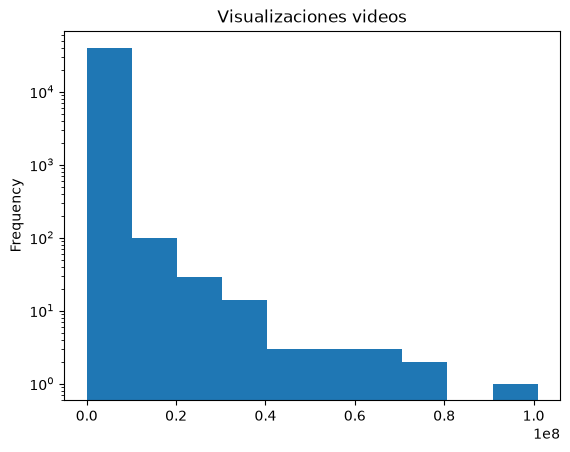

In [65]:
videos["visualizaciones"].plot(kind="hist",logy=True,title="Visualizaciones videos")

**4.4** Haz lo mismo con otra columna de números.

<Axes: title={'center': 'Comentarios en videos'}, ylabel='Frequency'>

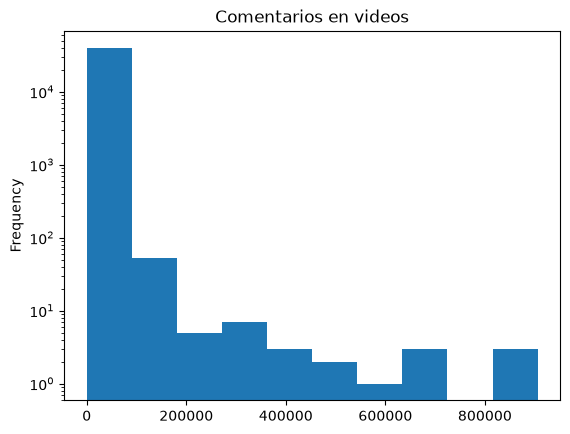

In [66]:
videos["numero comentarios"].plot(kind="hist",logy=True,title="Comentarios en videos")

Lo que he visto y lo que he decidido: Se observa que muy pocos vídeos concentran la mayoría de visualizaciones y comentarios, siendo los más virales.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [68]:
videos.sort_values("visualizaciones",ascending=False).head(5)

,id,fecha tendencia,titulo,titulo canal,id categoria,hora publicacion,etiquetas,visualizaciones,me gusta,no me gusta,numero comentarios,descripcion
5261,FlsCjmMhFmw,17.10.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06T17:58:51.000Z,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",100912384,2656698,1353667,682890,"YouTube Rewind 2017. Celebrating the videos, p..."
4998,FlsCjmMhFmw,17.09.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06T17:58:51.000Z,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",75969469,2251864,1127834,827784,"YouTube Rewind 2017. Celebrating the videos, p..."
3871,6ZfuNTqbHE8,17.03.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29T13:26:24.000Z,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",74789251,2444976,46173,330715,There was an idea… Avengers: Infinity War. In ...
3604,6ZfuNTqbHE8,17.02.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29T13:26:24.000Z,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",66637636,2331375,41155,316180,There was an idea… Avengers: Infinity War. In ...
35646,7C2z4GqqS5E,18.20.05,BTS (방탄소년단) 'FAKE LOVE' Official MV,ibighit,10,2018-05-18T09:00:02.000Z,"BIGHIT|""빅히트""|""방탄소년단""|""BTS""|""BANGTAN""|""방탄""|""FAK...",62796390,4470923,119053,905925,BTS (방탄소년단) 'FAKE LOVE' Official MVDirector : ...


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [69]:
videos.sort_values("visualizaciones")

,id,fecha tendencia,titulo,titulo canal,id categoria,hora publicacion,etiquetas,visualizaciones,me gusta,no me gusta,numero comentarios,descripcion
2561,AH9CPLoIWu4,17.26.11,RESUMEN CELAYA VS ALEBRIJES ASCENSO MX 2017,Ascenso MX,17,2017-11-26T06:05:11.000Z,"RESUMEN CELAYA VS ALEBRIJES ASCENSO MX 2017|""R...",157,16,3,7,RESUMEN CELAYA VS ALEBRIJES SEMIFINAL VUELTA A...
34091,IFUVQf_x3vU,18.11.05,Por Amar Sin Ley Capitulo 64 parte 4/4 - JUEVES,Marina Rios,24,2018-05-11T03:47:40.000Z,"hijas|""de""|""la""|""luna""|""las""|""juanas""|""ines""|""...",255,20,2,6,Para ver las siguientes partes solo le dan cli...
19666,mhALzepKrTc,18.22.02,Exatlon Avance programa 94 ¿Juego por la super...,Trend Tv,22,2018-02-22T05:07:00.000Z,"exatlón|""exatlón méxico""|""Ana lago""|""ana lago ...",269,29,4,27,"Avance del programa 94 del Exatlón México, ¿po..."
34690,gnHIBeDg0Vk,18.14.05,Omar Chaparro dedica palabras de aliento a Adr...,Videostendencias,22,2018-05-13T16:17:05.000Z,"Omar chaparro|""dedica""|""palabras""|""de""|""alient...",302,29,2,1,TE INVITAMOS A UNIRTE A NUESTRO NUEVO CANAL T...
14293,r0AXEVlTfgM,18.26.01,LA ULTIMA de Enamorandonos 25 de ENERO DEL 201...,VIRAL SHOW,24,2018-01-26T05:17:03.000Z,"la|""ultima""|""de""|""enamorandonos""|""25""|""enero""|...",328,14,27,2,LA ULTIMA de Enamorandonos 25 de ENERO DEL 201...
...,...,...,...,...,...,...,...,...,...,...,...,...
35793,7C2z4GqqS5E,18.20.05,BTS (방탄소년단) 'FAKE LOVE' Official MV,ibighit,10,2018-05-18T09:00:02.000Z,"BIGHIT|""빅히트""|""방탄소년단""|""BTS""|""BANGTAN""|""방탄""|""FAK...",62796390,4470923,119053,905925,BTS (방탄소년단) 'FAKE LOVE' Official MVDirector : ...
3604,6ZfuNTqbHE8,17.02.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29T13:26:24.000Z,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",66637636,2331375,41155,316180,There was an idea… Avengers: Infinity War. In ...
3871,6ZfuNTqbHE8,17.03.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29T13:26:24.000Z,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",74789251,2444976,46173,330715,There was an idea… Avengers: Infinity War. In ...
4998,FlsCjmMhFmw,17.09.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06T17:58:51.000Z,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",75969469,2251864,1127834,827784,"YouTube Rewind 2017. Celebrating the videos, p..."


**5.3** Haz el diagrama de caja de esa columna.

<Axes: >

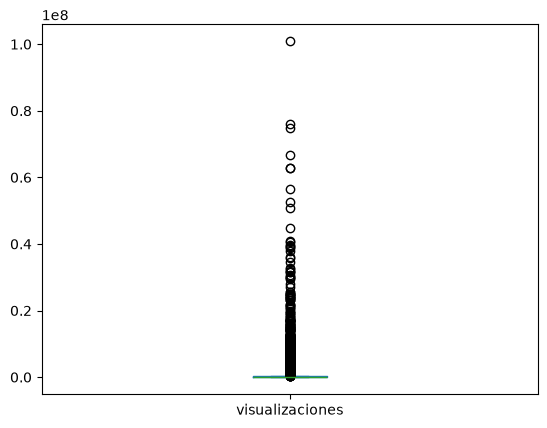

In [70]:
videos["visualizaciones"].plot(kind="box")

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido: Se ha visto que la mayoría de los vídeos concentran pocas visualizaciones y que solo unos pocos videos se llevan la mayoría de las visualizaciones, siendo los más virales. Al revisar los 5 valores más bajos, no se encontraron valores raros o nulos. Los valores altos no son errores, son videos que realmente tuvieron esas visualizaciones, así que no elimino ni corrijo ningún dato.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [73]:
print(videos["id categoria"].value_counts())
print(videos["id categoria"].value_counts(normalize=True*100).round(2))

id categoria
24    13487
22     8159
17     4050
10     3371
25     3113
26     2467
23     1742
1      1298
20      994
27      532
28      531
29      252
2       252
19      117
15       83
43        3
Name: count, dtype: int64
id categoria
24    0.33
22    0.20
17    0.10
10    0.08
25    0.08
26    0.06
23    0.04
1     0.03
20    0.02
27    0.01
28    0.01
29    0.01
2     0.01
19    0.00
15    0.00
43    0.00
Name: proportion, dtype: float64


**6.2** Dibújalo en barras.

<Axes: xlabel='id categoria'>

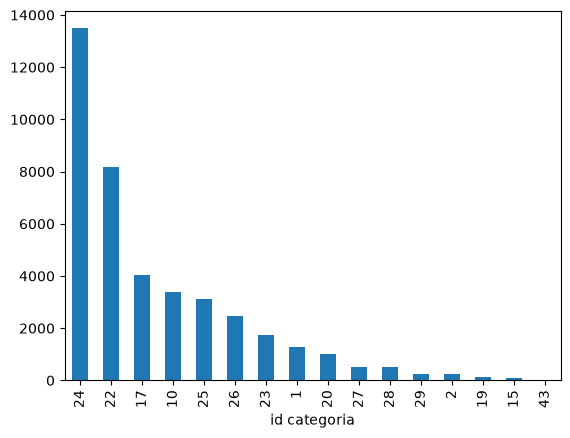

In [76]:
videos["id categoria"].value_counts().plot(kind="bar")

Lo que he visto y lo que he decidido: Se ha comprobado que en la categoría id 24 concentra el 0.33 por ciento de vídeos, siendo la mayor correspondiendo a un total de 13487 vídeos.

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [82]:
(videos.groupby("id categoria")["visualizaciones"].median())

id categoria
1      57111.5
2      55679.0
10    133056.0
15    122662.0
17    101036.0
19     72957.0
20    143930.0
22     29889.0
23    142119.5
24     60461.0
25     43055.0
26     28575.0
27     21446.0
28     77436.0
29     47497.0
43      4084.0
Name: visualizaciones, dtype: float64

**7.2** Haz otra comparación con otra columna de grupos.

In [90]:
(videos.groupby("id categoria")["me gusta"].mean()).round(2)

id categoria
1     13802.19
2     11828.94
10    67343.01
15    11933.83
17     7621.30
19     7672.73
20    24147.39
22     5865.80
23    31729.91
24    13842.41
25     3826.02
26     9992.34
27     4794.42
28     9631.96
29    11541.32
43      163.67
Name: me gusta, dtype: float64

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [91]:
videos.groupby("id categoria").size().sort_values()

id categoria
43        3
15       83
19      117
2       252
29      252
28      531
27      532
20      994
1      1298
23     1742
26     2467
25     3113
10     3371
17     4050
22     8159
24    13487
dtype: int64

Lo que he visto y lo que he decidido: Se ha visto que los grupos están desequilibrados, ya que en el grupo de la cateroría 43 hay solo 3 videos, por lo que su media no sería fiable, ya que un solo video puede alterarla mucho. En el otro extremo, tenemos la categoría 34 con 13487 videos. En este caso, se descartaría la categoría 43 y nos quedaríamos con los grupos de más de 80 vídeos.

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [93]:
print("visualizaciones y numero comentarios:", round(videos["visualizaciones"].corr(videos["numero comentarios"]),2))

visualizaciones y numero comentarios: 0.68


In [94]:
print("visualizaciones y categoria:", round(videos["id categoria"].corr(videos["visualizaciones"]),2))

visualizaciones y categoria: -0.1


**8.2** Haz el gráfico de puntos de esas dos columnas.

<Axes: xlabel='visualizaciones', ylabel='numero comentarios'>

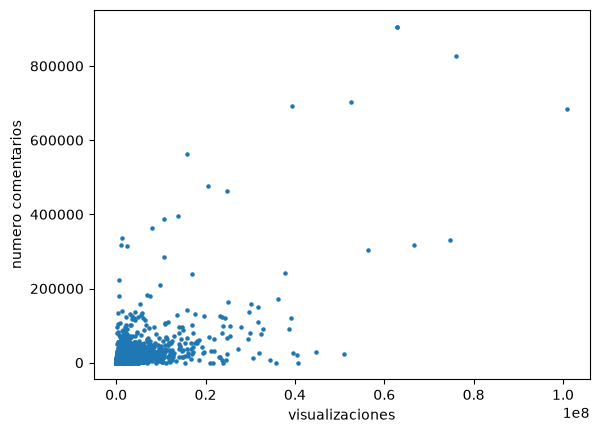

In [95]:
videos.plot(kind="scatter", x="visualizaciones", y="numero comentarios", s=5)

Lo que he visto y lo que he decidido: Vemos que hay una relación positiva, pero débil del 0.68%. Hay muchos videos de pocas visualizaciones y pocos comentarios, pero a medida que suben las visualizaciones, aumentan también los comentario. Sin embargo, hay algún video con muchas visualizaciones y pocos comentarios y eso podría deberse al tipo de tema o categoría de cada video.

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

Escribe aquí tus hallazgos.
1- Se ha descubierto que muy pocos vídeos son virales y tienen la gran mayoria de comentarios.
2- Observamos en la categoria 24 como tiene más videos pero no son los más virales respecto a las categorías 23,20 y 10 con menos vídeos y más virales.
3- Se han observado vídeos virales pero con 0 o pocos comentarios debido a la temática del vídeo, que no genera comentarios.

4- Nos hemos quedamos con las columnas más relevantes para el caso y se cambiaron a español. Se observó que la columna "descripción" tenía un 10 por ciento en huecos y se procedió a rellenarlos con "sin descripción". También se encontraron 49 filas duplicadas y se procedió a eliminarlas.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.